# Pandas Basics — Working with the "Aria" AI Assistant Dataset

Welcome! In this notebook you will learn the basics of the **Pandas** package by exploring
a (synthetic) dataset from a fictional AI assistant app called **Aria**.

Aria is a chatbot/AI-assistant product. The company logs information about its users:
who they are, how they use the app, how satisfied they are, and whether they trust the AI.
This is exactly the kind of dataset a **Human-Centered AI** professional works with all the
time: before you can design, evaluate, or improve an AI system, you need to be able to look
at data about the people who use it.

## How this notebook works

- The notebook is split into **4 parts**, each building on the previous one:
    1. Loading & first look at the data
    2. Basic exploration methods
    3. Visualizing your data
    4. Manipulating your data (the "harder" operations: missing data, new columns, `groupby`, `merge`, `pivot_table`)
- Every assignment is a **single, small step**. Don't skip ahead — each step assumes you've
  run the ones before it.
- Every assignment starts with a short explanation of the **concept** behind it — read this
  before you start coding. Pandas has a *lot* of methods; the goal of this notebook is not
  that you memorize them, but that you understand **what question each method answers** and
  **why** you'd want to ask it.
- Cells marked `# TODO` are for you to complete. Replace the `...` with real code.
- Some assignments end with a **"Think about it"** question. Answer these in a markdown cell
  or a code comment — there's no single "correct" sentence, but you should be able to justify
  your answer using the output you just produced.

## The data

Two files should be in the same folder as this notebook:

- `aria_users.csv` — one row per user of the Aria app (demographics, usage, satisfaction, ...)
- `aria_feature_usage.csv` — one row per (user, AI feature) combination, showing how often
  that user used that specific AI feature (e.g. "Translation", "Code Completion", ...). You'll
  use this second file later, for the `merge` assignment.

Let's get started!


## Part 1 — Loading & First Look at the Data

Before you can ask any question about data, you have to get it into your program in a shape
you can work with. In Pandas, that shape is called a **DataFrame**: think of it as a table,
like a spreadsheet, but one you can manipulate with code.


### 1.1 — Reading a CSV file

**Concept:** A CSV ("comma-separated values") file is just a plain text file where each line
is a row, and commas separate the columns. Pandas can read this into a `DataFrame` with one
function: `pd.read_csv()`. This is almost always the *first* line of code in any data project.

**Your task:**
- Import pandas using the conventional alias `pd`.
- Read `aria_users.csv` into a variable called `df`.
- Display the first 5 rows.


In [1]:
import pandas as pd

df = pd.read_csv("aria_users.csv")

df.head()


,user_id,age,country,region,education_level,device_type,subscription_type,signup_date,primary_use_case,daily_usage_minutes,sessions_per_week,monthly_spend_eur,trust_in_ai,satisfaction_score,nps_score,churned
0,1001,37.0,Sweden,Northern Europe,Master,Mobile,Free,2024-08-18,Personal Assistant,2.5,0,0.26,NaN,4.0,6,No
1,1002,23.0,Netherlands,Western Europe,Bachelor,Tablet,Free,2025-08-29,Coding,21.2,3,0.06,9.0,2.0,39,No
2,1003,42.0,France,Western Europe,PhD,Tablet,Free,2025-08-16,Writing,9.0,3,0.17,8.9,2.0,46,No
3,1004,44.0,Spain,Southern Europe,Bachelor,Mobile,Premium,2025-05-02,Coding,23.8,2,9.90,6.1,NaN,45,No
4,1005,16.0,Netherlands,Western Europe,Bachelor,Desktop,Free,2025-09-06,Coding,16.0,1,0.03,5.9,NaN,-4,No


### 1.2 — How big is the dataset?

**Concept:** Before analyzing anything, you should always know the **size** of your dataset:
how many rows (observations, e.g. users) and how many columns (variables, e.g. age, country)
it has. In a Human-Centered AI context this matters a lot: a dataset with 20 users tells you
something very different than one with 20,000 users — your confidence in any conclusion
depends on it.

**Your task:**
- Print the shape of `df` (rows, columns).
- Print the number of rows and the number of columns *separately*, in a readable sentence
  (e.g. `"This dataset has 623 rows and 16 columns"`).


In [2]:
print(df.shape)

n_rows = df.shape[0]
n_cols = df.shape[1]
print(f"This dataset has {n_rows} rows and {n_cols} columns")


(623, 16)
This dataset has 623 rows and 16 columns


### 1.3 — What kind of data is in each column?

**Concept:** Not all columns hold the same *kind* of data. Some are numbers you can do math
on (e.g. `age`), some are categories/labels (e.g. `country`), and some are dates. Pandas
tracks this per column as the **dtype** (data type). Knowing the dtype matters because it
determines which operations are even valid — you can compute an average `age`, but not an
average `country`.

**Your task:**
- Use `.info()` on `df` to see all columns, their dtypes, and how many non-missing values
  they have.
- Also inspect `.dtypes` directly.
- In a comment, write down: which 3 columns are clearly **categorical** (labels/groups), and
  which 3 are clearly **numeric**?


In [3]:
df.info()

df.dtypes

# categorical: country, subscription_type, primary_use_case
# numeric: age, daily_usage_minutes, monthly_spend_eur


<class 'pandas.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              623 non-null    int64  
 1   age                  599 non-null    float64
 2   country              623 non-null    str    
 3   region               623 non-null    str    
 4   education_level      623 non-null    str    
 5   device_type          623 non-null    str    
 6   subscription_type    623 non-null    str    
 7   signup_date          623 non-null    str    
 8   primary_use_case     623 non-null    str    
 9   daily_usage_minutes  623 non-null    float64
 10  sessions_per_week    623 non-null    int64  
 11  monthly_spend_eur    623 non-null    float64
 12  trust_in_ai          592 non-null    float64
 13  satisfaction_score   586 non-null    float64
 14  nps_score            623 non-null    int64  
 15  churned              623 non-null    str    
dtypes

user_id                  int64
age                    float64
country                    str
region                     str
education_level            str
device_type                str
subscription_type          str
signup_date                str
primary_use_case           str
daily_usage_minutes    float64
sessions_per_week        int64
monthly_spend_eur      float64
trust_in_ai            float64
satisfaction_score     float64
nps_score                int64
churned                    str
dtype: object

### 1.4 — A first statistical sanity check

**Concept:** `.describe()` computes summary statistics (count, mean, std, min, max, and the
quartiles) for every numeric column in one go. This is one of the most useful "first steps"
in any data project: it's a fast way to catch **obviously wrong values** before you draw any
conclusions — e.g. a negative amount of usage minutes, or an age of 300.

**Your task:**
- Run `.describe()` on `df` (numeric columns).
- Run `.describe(include='object')` to get equivalent statistics for the categorical
  (text) columns — note how the output looks different (e.g. it shows `top` and `freq`
  instead of `mean`).
- **Think about it:** Looking at the numeric summary, is there anything about
  `daily_usage_minutes` that looks like a data entry mistake? Write your answer in a comment.


In [4]:
df.describe()

,user_id,age,daily_usage_minutes,sessions_per_week,monthly_spend_eur,trust_in_ai,satisfaction_score,nps_score
count,623.000000,599.000000,623.000000,623.000000,623.000000,592.000000,586.000000,623.000000
mean,1310.096308,33.948247,25.145907,3.138042,5.528620,6.304392,3.385666,28.993579
std,178.840775,10.305484,22.096279,2.524519,6.990924,1.907856,0.943570,33.775930
min,1001.000000,16.000000,-12.000000,0.000000,0.000000,1.000000,1.000000,-72.000000
25%,1156.500000,26.000000,13.300000,1.000000,0.000000,5.000000,3.000000,5.500000
50%,1310.000000,34.000000,21.800000,3.000000,0.320000,6.300000,3.000000,28.000000
75%,1464.500000,40.500000,31.300000,4.000000,10.030000,7.700000,4.000000,53.000000
max,1620.000000,66.000000,251.800000,26.000000,20.660000,10.000000,5.000000,100.000000


In [5]:
df.describe(include="object")

# Think about it: yes — the minimum of daily_usage_minutes is negative, which is
# impossible (you cannot use an app for a negative number of minutes). This is almost
# certainly a data entry error and something we should deal with later.


C:\Users\joris\AppData\Local\Temp\ipykernel_11340\1330183901.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,country,region,education_level,device_type,subscription_type,signup_date,primary_use_case,churned
count,623,623,623,623,623,623,623,623
unique,10,4,4,9,3,388,6,2
top,Netherlands,Western Europe,Bachelor,Mobile,Free,2025-04-09,Coding,No
freq,151,411,267,315,360,5,142,510


## Part 2 — Basic Exploration Methods

Now that the data is loaded and you have a first impression, it's time to learn the "everyday"
methods you'll use constantly: selecting columns, counting categories, sorting, filtering, and
indexing.


### 2.1 — Selecting columns: Series vs. DataFrame

**Concept:** A DataFrame is made up of columns, and each individual column is a **Series**
(a 1-dimensional labeled array). There are two ways to select a column, and they give you
different *types* of object:
- `df['country']` → a **Series**
- `df[['country']]` → a **DataFrame** with just one column

This distinction trips up almost everyone at first, but it matters: some methods only work
on a Series, others expect a DataFrame.

**Your task:**
- Select the `country` column as a Series and store it in `country_series`.
- Select the `country` column as a DataFrame (using double brackets) and store it in
  `country_df`.
- Print the `type()` of both to confirm they're different.


In [6]:
country_series = df["country"]

country_df = df[["country"]]

print(type(country_series))
print(type(country_df))


<class 'pandas.Series'>
<class 'pandas.DataFrame'>


### 2.2 — Counting categories with `.value_counts()`

**Concept:** `.value_counts()` is one of the most important methods for a categorical column.
It counts **how many times each unique value occurs**. Conceptually, it turns a long column of
labels into a small frequency table — this is often the very first thing you want to know
about a categorical variable (e.g. "how many free vs. premium users do we have?").

**Your task:**
- Run `.value_counts()` on the `subscription_type` column. Note that the result is itself a
  Series, sorted from most to least common by default.
- Run it again with `normalize=True`. This turns the counts into **proportions** (they sum to 1).
- **Think about it:** What does each *row* in the output represent, and what does the
  *number* next to it represent? Does the sum of the raw counts equal the number of rows in
  `df`? Check this with code (don't just assume it).


In [7]:
df["subscription_type"].value_counts()

subscription_type
Free            360
Premium         186
Premium Plus     77
Name: count, dtype: int64

In [8]:
df["subscription_type"].value_counts(normalize=True)

subscription_type
Free            0.577849
Premium         0.298555
Premium Plus    0.123596
Name: proportion, dtype: float64

In [9]:
counts = df["subscription_type"].value_counts()
print(counts.sum() == len(df))
# Each row = one unique subscription type. Each number = how many users have that
# subscription type. Yes, the counts sum to len(df) because every user has exactly
# one subscription_type value (assuming no missing values in this column).


True


### 2.3 — `.unique()` and `.nunique()`: spotting messy categories

**Concept:** `.unique()` returns the *list* of distinct values in a column; `.nunique()`
returns *how many* distinct values there are. These are extremely useful for spotting data
quality problems: if a column that should only have 3 categories suddenly has 6, you probably
have inconsistent labels (e.g. `"Mobile"` vs `"mobile"` being treated as two different
categories).

**Your task:**
- Print the unique values of `device_type`.
- Print the number of unique values of `device_type`.
- **Think about it:** How many device types do you think there *should* conceptually be? Does
  `.nunique()` match that number? What's going on?


In [10]:
df["device_type"].unique()

<StringArray>
[ 'Mobile',  'Tablet', 'Desktop',  'MOBILE',  'mobile', 'desktop',  'TABLET',
 'DESKTOP',  'tablet']
Length: 9, dtype: str

In [11]:
df["device_type"].nunique()

# Think about it: conceptually there should be 3 device types (Mobile, Desktop, Tablet),
# but nunique() reports more. This is because some rows use different capitalization
# (e.g. "mobile" or "MOBILE" instead of "Mobile") -- Pandas treats these as different
# strings entirely, even though a human would consider them "the same". This is a classic
# real-world data-cleaning problem.


9

### 2.4 — Sorting with `.sort_values()`

**Concept:** Sorting reorders the rows of your DataFrame based on the values in one (or more)
columns. This is useful whenever you want to find extremes: the top spenders, the least
satisfied users, the most recent signups, etc.

**Your task:**
- Sort `df` by `daily_usage_minutes`, from highest to lowest (`ascending=False`).
- Store the result in `sorted_df` and show the top 10 rows, but only the columns
  `user_id`, `daily_usage_minutes`, and `subscription_type` (use double-bracket column
  selection, like in 2.1, combined with `.head()`).


In [12]:
sorted_df = df.sort_values("daily_usage_minutes", ascending=False)

sorted_df[["user_id", "daily_usage_minutes", "subscription_type"]].head(10)


,user_id,daily_usage_minutes,subscription_type
565,1566,251.8,Premium
40,1041,243.0,Free
371,1372,234.4,Premium Plus
104,1105,185.4,Free
235,1236,102.4,Free
168,1169,77.7,Premium
218,1219,75.7,Premium Plus
75,1076,74.8,Premium
564,1565,74.5,Premium
215,1216,68.9,Premium


### 2.5 — Filtering rows with boolean masks

**Concept:** This is one of the most important ideas in Pandas. Writing `df['satisfaction_score'] < 3`
doesn't give you filtered rows directly — it gives you a **Series of `True`/`False` values**,
one for each row (this is called a **boolean mask**). If you then put that mask inside
`df[...]`, Pandas keeps only the rows where the mask is `True`. You can combine multiple
conditions with `&` (and) / `|` (or) — each condition needs its own parentheses.

**Your task:**
- Create a boolean mask for users on the `"Premium"` subscription with a `satisfaction_score`
  below 3, and store it in a variable `mask`. Print `mask.head()` to see what it actually
  looks like.
- Use the mask to filter `df` and store the result in `unhappy_premium_users`.
- Print how many such users there are.


In [13]:
mask = (df["subscription_type"] == "Premium") & (df["satisfaction_score"] < 3)
print(mask.head())

unhappy_premium_users = df[mask]

print(len(unhappy_premium_users))


0    False
1    False
2    False
3    False
4    False
dtype: bool
21


### 2.6 — `.loc` and `.iloc`: two ways to select data

**Concept:** Pandas offers two complementary selection tools:
- `.loc[row_condition, column_names]` selects by **label** (column names) and/or boolean
  condition.
- `.iloc[row_positions, column_positions]` selects by **integer position**, just like
  indexing a Python list — it doesn't care about labels at all.

A common rule of thumb: use `.loc` when you know *what* you want by name/condition, use
`.iloc` when you know *where* it is by position.

**Your task:**
- Use `.loc` to select the `user_id`, `country`, and `trust_in_ai` columns, but only for rows
  where `trust_in_ai` is greater than 8.
- Use `.iloc` to select the first 5 rows and only the 1st and 3rd columns (by position).


In [14]:
high_trust = df.loc[df["trust_in_ai"] > 8, ["user_id", "country", "trust_in_ai"]]
high_trust

df.iloc[0:5, [0, 2]]


,user_id,country
0,1001,Sweden
1,1002,Netherlands
2,1003,France
3,1004,Spain
4,1005,Netherlands


### 2.7 — Detecting missing data with `.isnull()`

**Concept:** Real-world data almost always has gaps: a user who didn't answer a survey
question, a sensor that failed to log a value, etc. In Pandas, missing values show up as
`NaN`. Before you do *any* serious analysis, you should know exactly how much data is
missing, and where — otherwise you risk drawing conclusions from an incomplete (and possibly
biased) subset of your data.

**Your task:**
- Use `.isnull()` combined with `.sum()` to count the number of missing values **per column**.
- Turn that into a **percentage** of missing values per column (divide by `len(df)` and
  multiply by 100).
- **Think about it:** Which column has the most missing data? Why might *that specific*
  column (rather than some other one) be more likely to have missing values in a real
  AI-assistant product? (Hint: think about how the data might have been collected.)


In [15]:
missing_counts = df.isnull().sum()
print(missing_counts)

missing_pct = (df.isnull().sum() / len(df)) * 100
print(missing_pct)

# Think about it: satisfaction_score and trust_in_ai tend to have the most missing values.
# This makes sense because these are typically collected through optional in-app surveys
# (e.g. "how satisfied are you?") which not every user bothers to answer -- unlike usage
# statistics like daily_usage_minutes, which the app can log automatically without asking
# the user anything.


user_id                 0
age                    24
country                 0
region                  0
education_level         0
device_type             0
subscription_type       0
signup_date             0
primary_use_case        0
daily_usage_minutes     0
sessions_per_week       0
monthly_spend_eur       0
trust_in_ai            31
satisfaction_score     37
nps_score               0
churned                 0
dtype: int64
user_id                0.000000
age                    3.852327
country                0.000000
region                 0.000000
education_level        0.000000
device_type            0.000000
subscription_type      0.000000
signup_date            0.000000
primary_use_case       0.000000
daily_usage_minutes    0.000000
sessions_per_week      0.000000
monthly_spend_eur      0.000000
trust_in_ai            4.975923
satisfaction_score     5.939005
nps_score              0.000000
churned                0.000000
dtype: float64


## Part 3 — Visualizing Your Data

Tables of numbers are precise, but humans are much better at spotting patterns, outliers, and
trends in a **picture**. Pandas has built-in plotting (via `matplotlib`) that lets you go from
DataFrame to chart in a single line of code — perfect for quick exploration.

Run this cell first to make sure plots show up nicely in the notebook.


In [16]:
import matplotlib.pyplot as plt
%matplotlib inline


### 3.1 — Histograms: the distribution of a numeric variable

**Concept:** A histogram splits the range of a numeric variable into "bins" and counts how
many rows fall into each bin. It answers the question: *"what does the distribution of this
variable look like?"* — is it symmetric, skewed, does it have multiple peaks, are there
outliers far away from the rest?

**Your task:**
- Plot a histogram of the `age` column using `df['age'].plot(kind='hist', bins=20)`.
- Add a title ("Distribution of user age") and an x-axis label ("Age") using
  `plt.title()` and `plt.xlabel()`, then `plt.show()`.


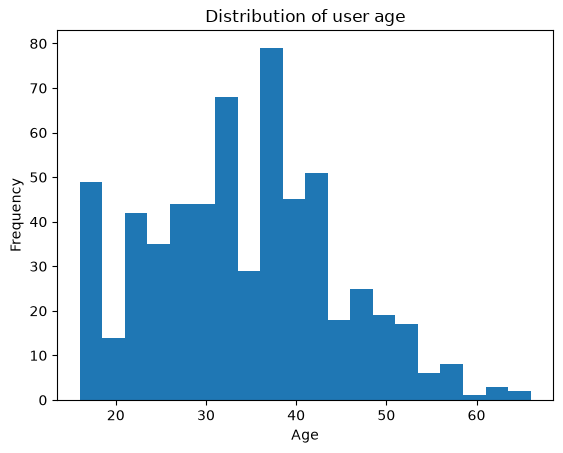

In [17]:
df["age"].plot(kind="hist", bins=20)

plt.title("Distribution of user age")
plt.xlabel("Age")
plt.show()


### 3.2 — Bar charts: visualizing `.value_counts()`

**Concept:** A histogram is for *continuous* numeric variables (like age); a **bar chart** is
for *categorical* variables (like `primary_use_case`). A very common pattern is to first
compute `.value_counts()` (Part 2.2) and then immediately call `.plot(kind='bar')` on the
result — turning a frequency table into a picture in two lines.

**Your task:**
- Compute `.value_counts()` on `primary_use_case`.
- Plot it as a bar chart.
- Add a title and a y-axis label ("Number of users"), then show the plot.


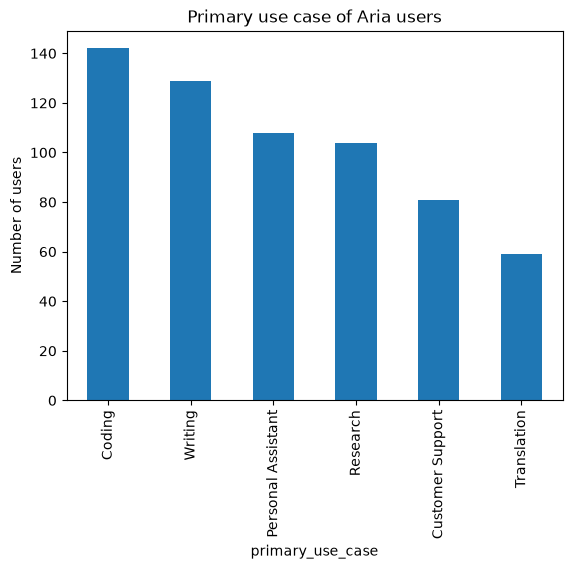

In [18]:
df["primary_use_case"].value_counts().plot(kind="bar")

plt.title("Primary use case of Aria users")
plt.ylabel("Number of users")
plt.show()


### 3.3 — Boxplots: comparing groups and spotting outliers

**Concept:** A boxplot summarizes a numeric variable using its median, quartiles, and
outliers, shown as a "box" with whiskers and individual dots for extreme values. Boxplots
become especially powerful when you draw one **per group**: it lets you compare a numeric
variable (e.g. usage) *across* categories (e.g. subscription type) at a glance, including
whether one group has more outliers than another.

**Your task:**
- Use `df.boxplot(column='daily_usage_minutes', by='subscription_type')` to compare daily
  usage across subscription types.
- Add a title, then `plt.show()`.
- **Think about it:** Can you spot the negative outlier from assignment 1.4 in this plot?
  Which subscription group does it belong to?


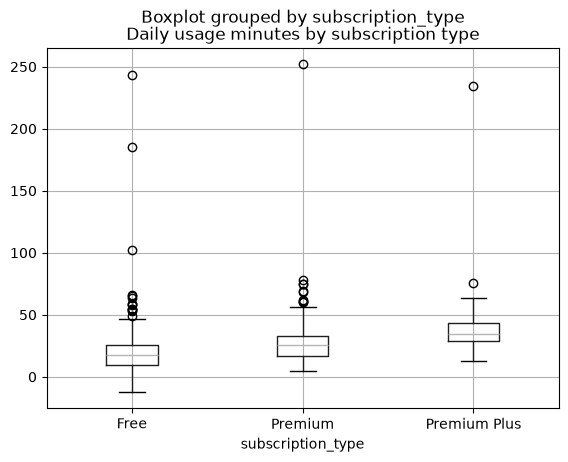

In [19]:
df.boxplot(column="daily_usage_minutes", by="subscription_type")

plt.title("Daily usage minutes by subscription type")
plt.show()

# Think about it: yes, there is a point far below zero — this is the impossible negative
# value we spotted in 1.4. Since it's an obvious data-entry mistake, we should not use it
# as-is in later analysis (see Part 4.1 on handling problematic/missing values).


### 3.4 — Scatter plots: relationships between two numeric variables

**Concept:** A scatter plot places one point per row, positioned by two numeric variables —
one on the x-axis, one on the y-axis. It's the go-to chart for asking: *"as X goes up, does Y
tend to go up, go down, or stay the same?"* — i.e., is there a relationship between the two?

**Your task:**
- Make a scatter plot of `age` (x-axis) versus `daily_usage_minutes` (y-axis) using
  `df.plot(kind='scatter', x=..., y=...)`.
- Add a title, then show the plot.
- **Think about it:** Based on the plot, does there seem to be a clear relationship between
  a user's age and how much they use Aria per day? Would you expect one, conceptually?


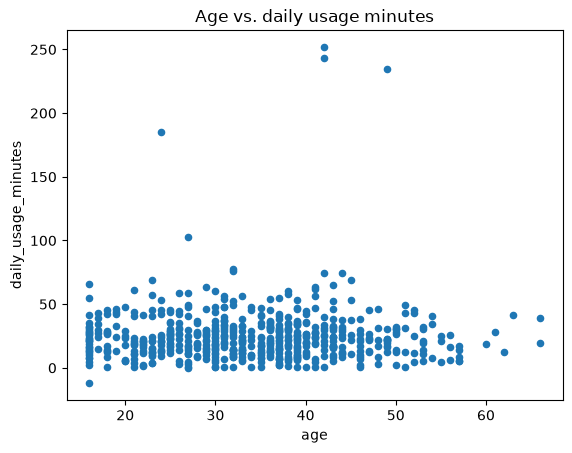

In [20]:
df.plot(kind="scatter", x="age", y="daily_usage_minutes")

plt.title("Age vs. daily usage minutes")
plt.show()

# Think about it: there is no strong, obvious pattern here -- the points form a fairly
# random-looking cloud, suggesting age alone doesn't explain much about usage in this
# (synthetic) dataset. That's a perfectly valid and useful conclusion: not every variable
# you plot has to show a relationship.


## Part 4 — Manipulating Your Data

So far you've explored the data as-is. Now you'll learn how to **transform** it: cleaning up
problems you found, creating new columns from existing ones, and — the most powerful tool in
this notebook — **grouping and aggregating** data to answer real questions. This is where the
"programmer mindset" you already practiced comes back: each of these operations is a small,
composable building block, and real analyses are built by chaining several of them together.


### 4.1 — Handling missing and invalid values

**Concept:** Once you've *found* missing or invalid values (Part 1.4 and 2.7), you have to
decide what to do about them. There is no single "correct" method — it's a trade-off:
- `.dropna()` removes rows with missing values entirely — simple, but you lose data (and if
  the missingness isn't random, you can bias your results).
- `.fillna(value)` fills gaps with something sensible, like the median or mean — you keep all
  your rows, but you're "inventing" data that wasn't really there.

We also have that one impossible negative value in `daily_usage_minutes` from assignment 1.4
— that's not "missing", it's simply *wrong*, so the fix is different: we replace it, e.g. with
the column's median.

**Your task:**
- Replace the impossible negative value(s) in `daily_usage_minutes` with the column's median.
  (Hint: build a boolean mask for `daily_usage_minutes < 0`, then use `.loc[mask, 'daily_usage_minutes'] = ...`.)
- Fill missing values in `satisfaction_score` with the column's median using `.fillna()`.
- Drop any remaining rows that still have a missing `age` using `.dropna(subset=['age'])`,
  and store the result back into `df`.
- Print `df.isnull().sum()` again to confirm the missing values you targeted are gone.


In [21]:
median_usage = df["daily_usage_minutes"].median()
mask = df["daily_usage_minutes"] < 0
df.loc[mask, "daily_usage_minutes"] = median_usage

df["satisfaction_score"] = df["satisfaction_score"].fillna(df["satisfaction_score"].median())

df = df.dropna(subset=["age"])

df.isnull().sum()


user_id                 0
age                     0
country                 0
region                  0
education_level         0
device_type             0
subscription_type       0
signup_date             0
primary_use_case        0
daily_usage_minutes     0
sessions_per_week       0
monthly_spend_eur       0
trust_in_ai            31
satisfaction_score      0
nps_score               0
churned                 0
dtype: int64

### 4.2 — Creating new columns with vectorized operations

**Concept:** In plain Python, you might use a `for` loop to compute something for every row.
Pandas lets you skip the loop entirely: writing `df['a'] * 7` performs that multiplication for
*every row at once* — this is called a **vectorized operation**, and it's both much shorter to
write and much faster to run than looping manually. Whenever a computation can be expressed
this way, prefer it over a loop.

**Your task:**
- Create a new column `weekly_usage_minutes` = `daily_usage_minutes * 7`.
- Create a new boolean column `is_heavy_user` that is `True` when `daily_usage_minutes > 30`.
- Show `df[['daily_usage_minutes', 'weekly_usage_minutes', 'is_heavy_user']].head()` to check
  your work.


In [22]:
df["weekly_usage_minutes"] = df["daily_usage_minutes"] * 7

df["is_heavy_user"] = df["daily_usage_minutes"] > 30

df[["daily_usage_minutes", "weekly_usage_minutes", "is_heavy_user"]].head()


,daily_usage_minutes,weekly_usage_minutes,is_heavy_user
0,2.5,17.5,False
1,21.2,148.4,False
2,9.0,63.0,False
3,23.8,166.6,False
4,16.0,112.0,False


### 4.3 — `.apply()` with a custom function: when vectorization isn't enough

**Concept:** Sometimes the logic you need is more complex than a simple arithmetic operation
— for example, sorting a numeric value into one of several named "buckets". For this, Pandas
offers `.apply()`, which runs your **own function** on every value (or every row) of a column.
It's more flexible than vectorized operations, but also generally slower — so it's a good tool
to reach for, but not the *first* one, when a simpler vectorized approach exists.

**Your task:**
- Write a function `age_to_group(age)` that returns:
    - `"<25"` if age is below 25
    - `"25-40"` if age is between 25 (inclusive) and 40 (exclusive)
    - `"40-60"` if age is between 40 (inclusive) and 60 (exclusive)
    - `"60+"` otherwise
- Use `.apply()` to create a new column `age_group` from the `age` column using this function.
- Use `.value_counts()` (Part 2.2!) on `age_group` to check the result.


In [23]:
def age_to_group(age):
    if age < 25:
        return "<25"
    elif age < 40:
        return "25-40"
    elif age < 60:
        return "40-60"
    else:
        return "60+"

df["age_group"] = df["age"].apply(age_to_group)

df["age_group"].value_counts()


age_group
25-40    314
40-60    160
<25      119
60+        6
Name: count, dtype: int64

### 4.4 — `groupby`: split, apply, combine

**Concept:** `groupby` is arguably *the* most important concept in Pandas, and it works in
three conceptual steps (this pattern is called "split-apply-combine"):
1. **Split** the data into groups based on a column (e.g. one group per `subscription_type`).
2. **Apply** a calculation to each group separately (e.g. compute the mean `satisfaction_score`).
3. **Combine** the per-group results back into a single table.

It answers questions of the shape *"how does \[some number\] differ across \[some category\]?"*
— exactly the kind of question that matters in Human-Centered AI: does trust in the AI differ
between user groups? Does satisfaction differ by use case?

**Your task:**
- Group `df` by `subscription_type` and compute the mean `satisfaction_score` for each group.
- Do the same for `daily_usage_minutes`.
- **Think about it:** Before running the code — what result would you *expect*? Free users
  probably behave differently from Premium Plus users; in what way, and why? Write your
  prediction *first*, then compare it to the actual output.


In [24]:
# Prediction: paying (Premium/Premium Plus) users are probably somewhat more satisfied
# and/or use the app more, since they've chosen to pay for it.

df.groupby("subscription_type")["satisfaction_score"].mean()

df.groupby("subscription_type")["daily_usage_minutes"].mean()


subscription_type
Free            20.540058
Premium         28.935000
Premium Plus    38.041667
Name: daily_usage_minutes, dtype: float64

### 4.5 — `groupby` with multiple columns and multiple aggregations

**Concept:** You can group by more than one column at once (e.g. subscription type *and* use
case), and compute more than one statistic at once using `.agg()`. This lets you build much
richer summaries in a single line, at the cost of a slightly more complex result to read.

**Your task:**
- Group `df` by **both** `subscription_type` and `primary_use_case`.
- Use `.agg()` to compute, per group: the **count** of users (`'user_id': 'count'`) and the
  **mean** `monthly_spend_eur` (`'monthly_spend_eur': 'mean'`).
  (Hint: `.agg({'user_id': 'count', 'monthly_spend_eur': 'mean'})`)
- Store the result in `grouped_summary` and display it.


In [25]:
grouped_summary = (
    df.groupby(["subscription_type", "primary_use_case"])
      .agg({"user_id": "count", "monthly_spend_eur": "mean"})
)
grouped_summary


user_id  monthly_spend_eur
subscription_type primary_use_case                              
Free              Coding                   72           0.132778
                  Customer Support         52           0.111346
                  Personal Assistant       61           0.152131
                  Research                 55           0.103818
                  Translation              32           0.108438
                  Writing                  75           0.107733
Premium           Coding                   47           9.971489
                  Customer Support         15          10.014000
                  Personal Assistant       30          10.017667
                  Research                 36          10.040278
                  Translation              20           9.953000
                  Writing                  32          10.070312
Premium Plus      Coding                   19          19.896842
                  Customer Support          9          20.194444
                  Personal Assistant        8          19.981250
                  Research                 10          19.915000
                  Translation               6          20.041667
                  Writing                  20          20.018500

### 4.6 — Reshaping summaries with `.pivot_table()`

**Concept:** The output of the previous assignment is a bit hard to scan visually because
both grouping columns are stacked on the rows. A **pivot table** reshapes this: one grouping
column becomes the rows, the other becomes the columns, and the cells contain the aggregated
value — exactly like a pivot table in Excel. This is often much easier for a human to read at
a glance, which matters a lot when you need to *communicate* your findings to others.

**Your task:**
- Build a pivot table with `primary_use_case` as the row index, `subscription_type` as the
  columns, `satisfaction_score` as the values, and `aggfunc='mean'`.
  (Hint: `df.pivot_table(index=..., columns=..., values=..., aggfunc=...)`)
- **Think about it:** Which combination of use case and subscription type has the *highest*
  average satisfaction? Which has the *lowest*? (You can eyeball this, or use `.max()`/`.min()`
  if you're feeling adventurous.)


In [26]:
pivot = df.pivot_table(
    index="primary_use_case", columns="subscription_type",
    values="satisfaction_score", aggfunc="mean"
)
pivot

# Think about it: answers will vary slightly depending on the random data / how missing
# values were handled in 4.1, but students should point to the actual highest and lowest
# cell in their own pivot table output.


subscription_type,Free,Premium,Premium Plus
primary_use_case,,,
Coding,3.111111,3.446809,3.368421
Customer Support,3.134615,4.066667,3.000000
Personal Assistant,3.442623,3.633333,3.125000
Research,3.400000,3.305556,3.800000
Translation,3.218750,3.700000,3.833333
Writing,3.360000,3.312500,3.850000


### 4.7 — Combining two datasets with `.merge()`

**Concept:** Real projects rarely live in a single table. Here, `aria_feature_usage.csv`
contains a *separate* log: one row per (user, AI feature) combination, e.g. "user 1001 used
Translation 17 times". To connect this to our main `df`, we need to **merge** the two tables
on a shared key column — here, `user_id`. This is the same idea as a `JOIN` in SQL, and it's
essential any time your data about one entity (a user) is spread across multiple sources.

**Your task:**
- Read `aria_feature_usage.csv` into a new DataFrame `feature_df`.
- Group `feature_df` by `user_id` and sum `times_used`, to get one row per user with their
  *total* number of feature uses. Store this in `total_feature_uses` (Series or DataFrame —
  your choice, but you'll need a `user_id` column to merge on, so consider `.reset_index()`).
- Merge this into `df` using `pd.merge(df, total_feature_uses, on='user_id', how='left')`,
  and store the result in `df_merged`.
- **Think about it:** why did we use `how='left'` here instead of `how='inner'`? What would
  happen to users who don't appear at all in `aria_feature_usage.csv` under each option?


In [27]:
feature_df = pd.read_csv("aria_feature_usage.csv")

total_feature_uses = (
    feature_df.groupby("user_id")["times_used"].sum().reset_index()
)

df_merged = pd.merge(df, total_feature_uses, on="user_id", how="left")
df_merged.head()

# Think about it: a 'left' join keeps every row of df (our main user table) no matter what,
# filling in NaN for users who happen to have no rows in aria_feature_usage.csv (i.e. they
# never used any AI feature). An 'inner' join would silently DROP those users entirely,
# which could bias later analysis (e.g. it would look like every user uses at least one
# feature, which isn't true).


,user_id,age,country,region,education_level,device_type,subscription_type,signup_date,primary_use_case,daily_usage_minutes,sessions_per_week,monthly_spend_eur,trust_in_ai,satisfaction_score,nps_score,churned,weekly_usage_minutes,is_heavy_user,age_group,times_used
0,1001,37.0,Sweden,Northern Europe,Master,Mobile,Free,2024-08-18,Personal Assistant,2.5,0,0.26,NaN,4.0,6,No,17.5,False,25-40,34
1,1002,23.0,Netherlands,Western Europe,Bachelor,Tablet,Free,2025-08-29,Coding,21.2,3,0.06,9.0,2.0,39,No,148.4,False,<25,44
2,1003,42.0,France,Western Europe,PhD,Tablet,Free,2025-08-16,Writing,9.0,3,0.17,8.9,2.0,46,No,63.0,False,40-60,18
3,1004,44.0,Spain,Southern Europe,Bachelor,Mobile,Premium,2025-05-02,Coding,23.8,2,9.90,6.1,3.0,45,No,166.6,False,40-60,27
4,1005,16.0,Netherlands,Western Europe,Bachelor,Desktop,Free,2025-09-06,Coding,16.0,1,0.03,5.9,3.0,-4,No,112.0,False,<25,28


### 4.8 — Capstone: put it all together

**Concept:** Real analysis is rarely a single method call — it's a short *chain* of the
building blocks you've now learned: filter, group, aggregate, sort. This last assignment asks
you to combine several of them to answer one concrete, realistic Human-Centered AI question.

**Question to answer:** *Among users classified as `is_heavy_user` (Part 4.2), which
`primary_use_case` group has the lowest average `trust_in_ai`, and how does its churn rate
(`churned == 'Yes'`) compare to the other use cases?*

**Your task (there is no single "right" code path — plan your steps first!):**
1. Filter `df_merged` (or `df`) to only heavy users.
2. Group by `primary_use_case` and compute the mean `trust_in_ai`.
3. Sort this to find the lowest-trust use case.
4. Separately, group by `primary_use_case` and compute the *proportion* of users with
   `churned == 'Yes'` (hint: the mean of a boolean column gives you a proportion!).
5. Write 2–3 sentences (in a markdown cell) interpreting what you found, and what a product
   team at Aria might want to do about it.


In [28]:
heavy_users = df_merged[df_merged["is_heavy_user"]]

trust_by_use_case = (
    heavy_users.groupby("primary_use_case")["trust_in_ai"].mean().sort_values()
)
trust_by_use_case

churn_by_use_case = (
    heavy_users.groupby("primary_use_case")["churned"]
    .apply(lambda s: (s == "Yes").mean())
    .sort_values(ascending=False)
)
churn_by_use_case

# Example interpretation (yours may differ depending on the random data):
# The use case with the lowest average trust_in_ai among heavy users also tends to show
# a relatively higher churn rate. This suggests that trust in the AI's output for that
# particular task may be a driver of people leaving the product, even among users who
# are otherwise highly engaged (heavy users). A product team might prioritize improving
# transparency or accuracy of the AI for that specific use case.


primary_use_case
Personal Assistant    0.200000
Writing               0.184211
Research              0.181818
Customer Support      0.117647
Translation           0.111111
Coding                0.108108
Name: churned, dtype: float64

## You made it!

You've now used Pandas to load, inspect, clean, visualize, and transform a realistic dataset
— and along the way you touched almost every method you'll use on a daily basis as a Human-
Centered AI practitioner: `read_csv`, `.info()`, `.describe()`, `.value_counts()`, boolean
filtering, `.loc`/`.iloc`, plotting, `.fillna()`/`.dropna()`, `.apply()`, `.groupby()`,
`.pivot_table()`, and `.merge()`.

**A final reflection question:** Which single method in this notebook do you think will be
the most useful *for the kind of work you personally want to do* in Human-Centered AI, and
why? There's no wrong answer — write a few sentences in a markdown cell below.
